### CRISP-DM · Fase 5: Evaluación

Evaluación del modelo final con el grupo de prueba y verificación de los criterios de éxito definidos en la fase 1.

- **Entradas:** `crisp_dm/data/interim/test_clean.csv`, `crisp_dm/data/interim/success_criteria.json`, `crisp_dm/models/svm.joblib`, `crisp_dm/models/baseline.joblib`, `crisp_dm/data/processed/cv_results.csv`
- **Salidas:**
  - `crisp_dm/data/processed/metrics.csv`: métricas globales
  - `crisp_dm/data/processed/class_report.csv`: métricas por especie
  - `crisp_dm/data/processed/misclassified.csv`: registros mal clasificados
  - `crisp_dm/data/processed/success_check.csv`: verificación de los criterios de éxito
  - `crisp_dm/figures/evaluation_confusion_matrix.png`: matriz de confusión

#### Librerías

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)

#### Rutas

Relativas a la carpeta del notebook.

In [2]:
INTERIM_DIR = Path("../data/interim")
PROCESSED_DIR = Path("../data/processed")
MODELS_DIR = Path("../models")
FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

#### Carga de datos, criterios y modelos

In [3]:
test = pd.read_csv(INTERIM_DIR / "test_clean.csv")
with open(INTERIM_DIR / "success_criteria.json", encoding="utf-8") as f:
    success_criteria = json.load(f)

TARGET = "species"
NUMERIC = ["culmen_length_mm", "culmen_depth_mm", "flipper_length_mm", "body_mass_g"]
CATEGORICAL = ["island", "sex"]
FEATURES = NUMERIC + CATEGORICAL
SPECIES = ["Adelie", "Chinstrap", "Gentoo"]

X_test = test[FEATURES]
y_test = test[TARGET]

models = {
    "baseline_most_frequent": joblib.load(MODELS_DIR / "baseline.joblib"),
    "svm": joblib.load(MODELS_DIR / "svm.joblib"),
}

print(f"Registros de prueba: {len(X_test)}")
success_criteria

Registros de prueba: 69


{'f1_macro_min': 0.95, 'recall_min_per_species': 0.9, 'review_threshold': 0.8}

#### Predicciones

In [4]:
predictions = {name: model.predict(X_test) for name, model in models.items()}

#### Métricas globales

In [5]:
metrics = pd.DataFrame([
    {
        "modelo": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
        "f1_macro": f1_score(y_test, y_pred, average="macro"),
        "errores": int((y_pred != y_test).sum()),
        "n": len(y_test),
    }
    for name, y_pred in predictions.items()
]).round(4)
metrics

,modelo,accuracy,balanced_accuracy,f1_macro,errores,n
0,baseline_most_frequent,0.4348,0.3333,0.202,39,69
1,svm,1.0000,1.0000,1.000,0,69


#### Validación cruzada frente a prueba

In [6]:
cv_results = pd.read_csv(PROCESSED_DIR / "cv_results.csv")
cv_base = cv_results[cv_results["modelo"] == "baseline_most_frequent"].iloc[0]
cv_svm = cv_results[cv_results["modelo"] == "svm"].sort_values("rank").iloc[0]

pd.DataFrame({
    "f1_macro_cv": [cv_base["f1_macro_mean"], cv_svm["f1_macro_mean"]],
    "f1_macro_test": metrics["f1_macro"].values,
}, index=metrics["modelo"]).round(4)

,f1_macro_cv,f1_macro_test
modelo,,
baseline_most_frequent,0.2047,0.202
svm,1.0000,1.000


#### Métricas por especie

In [7]:
y_pred = predictions["svm"]

class_report = pd.DataFrame(
    classification_report(y_test, y_pred, output_dict=True, zero_division=0)
).T.drop(index="accuracy").round(4)
class_report["support"] = class_report["support"].astype(int)
class_report

,precision,recall,f1-score,support
Adelie,1.0,1.0,1.0,30
Chinstrap,1.0,1.0,1.0,14
Gentoo,1.0,1.0,1.0,25
macro avg,1.0,1.0,1.0,69
weighted avg,1.0,1.0,1.0,69


#### Matriz de confusión

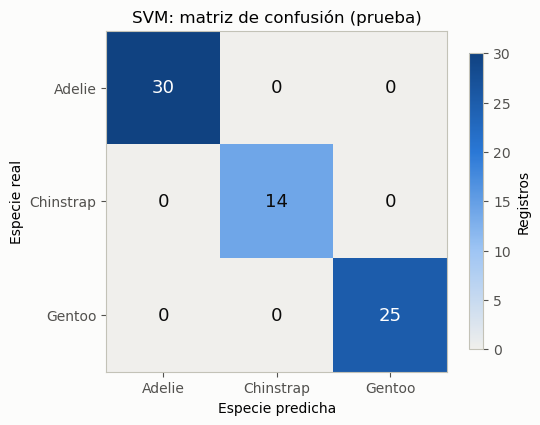

In [8]:
cm = confusion_matrix(y_test, y_pred, labels=SPECIES)

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "font.size": 10, "savefig.dpi": 150, "savefig.bbox": "tight",
})
cmap = LinearSegmentedColormap.from_list("seq", ["#f0efec", "#9ec5f4", "#2a78d6", "#104281"])

fig, ax = plt.subplots(figsize=(5.5, 4.8))
im = ax.imshow(cm, cmap=cmap)
for i in range(len(SPECIES)):
    for j in range(len(SPECIES)):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13,
                color="#ffffff" if cm[i, j] > cm.max() / 2 else "#0b0b0b")
ax.set_xticks(range(len(SPECIES)), SPECIES)
ax.set_yticks(range(len(SPECIES)), SPECIES)
ax.set_xlabel("Especie predicha")
ax.set_ylabel("Especie real")
ax.set_title("SVM: matriz de confusión (prueba)")
fig.colorbar(im, ax=ax, shrink=0.8, label="Registros")
fig.savefig(FIGURES_DIR / "evaluation_confusion_matrix.png")
plt.show()

#### Registros mal clasificados

In [9]:
model = models["svm"]
proba = pd.DataFrame(
    model.predict_proba(X_test),
    columns=[f"prob_{c}" for c in model.classes_],
    index=test.index,
).round(3)

results = pd.concat([test, proba], axis=1)
results["predicted"] = y_pred

misclassified = results[results["predicted"] != results[TARGET]]
print(f"Registros mal clasificados: {len(misclassified)} de {len(results)}")
misclassified

Registros mal clasificados: 0 de 69


,row_id,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex,prob_Adelie,prob_Chinstrap,prob_Gentoo,predicted


#### Registros para revisión manual

Predicciones con probabilidad máxima menor que el umbral de revisión.

In [10]:
threshold = success_criteria["review_threshold"]
results["max_prob"] = proba.max(axis=1)
results["revision"] = results["max_prob"] < threshold

review = results[results["revision"]]
print(f"Registros marcados para revisión: {len(review)} de {len(results)}")
print(f"Errores dentro de los marcados: {(review['predicted'] != review[TARGET]).sum()} de {len(misclassified)}")
review

Registros marcados para revisión: 0 de 69
Errores dentro de los marcados: 0 de 0


,row_id,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex,prob_Adelie,prob_Chinstrap,prob_Gentoo,predicted,max_prob,revision


#### Verificación de los criterios de éxito

In [11]:
min_recall = class_report.loc[SPECIES, "recall"].min()
f1_macro = metrics.loc[metrics["modelo"] == "svm", "f1_macro"].iloc[0]
errors_flagged = (review["predicted"] != review[TARGET]).sum()

success_check = pd.DataFrame([
    {
        "criterio": "F1 macro en prueba",
        "meta": f">= {success_criteria['f1_macro_min']}",
        "resultado": round(f1_macro, 4),
        "cumple": f1_macro >= success_criteria["f1_macro_min"],
    },
    {
        "criterio": "Sensibilidad mínima por especie",
        "meta": f">= {success_criteria['recall_min_per_species']}",
        "resultado": round(min_recall, 4),
        "cumple": min_recall >= success_criteria["recall_min_per_species"],
    },
    {
        "criterio": "Registros marcados para revisión",
        "meta": f"probabilidad < {threshold}",
        "resultado": f"{len(review)} de {len(results)}",
        "cumple": True,
    },
])
success_check

,criterio,meta,resultado,cumple
0,F1 macro en prueba,>= 0.95,1.0,True
1,Sensibilidad mínima por especie,>= 0.9,1.0,True
2,Registros marcados para revisión,probabilidad < 0.8,0 de 69,True


#### Guardado de resultados

In [12]:
metrics.to_csv(PROCESSED_DIR / "metrics.csv", index=False)
class_report.to_csv(PROCESSED_DIR / "class_report.csv")
misclassified.to_csv(PROCESSED_DIR / "misclassified.csv", index=False)
success_check.to_csv(PROCESSED_DIR / "success_check.csv", index=False)

for path in [
    PROCESSED_DIR / "metrics.csv",
    PROCESSED_DIR / "class_report.csv",
    PROCESSED_DIR / "misclassified.csv",
    PROCESSED_DIR / "success_check.csv",
    FIGURES_DIR / "evaluation_confusion_matrix.png",
]:
    print(f"Guardado: {path}")

Guardado: ..\data\processed\metrics.csv
Guardado: ..\data\processed\class_report.csv
Guardado: ..\data\processed\misclassified.csv
Guardado: ..\data\processed\success_check.csv
Guardado: ..\figures\evaluation_confusion_matrix.png
